In [1]:
%matplotlib inline
%precision 16

import numpy
import matplotlib.pyplot as plt

Before you turn this problem in, make sure everything runs as expected. First, restart the kernel (in the menubar, select Kernel $\rightarrow$ Restart) and then run all cells (in the menubar, select Cell $\rightarrow$ Run All).

Make sure you fill in any place that says YOUR CODE HERE or "YOUR ANSWER HERE", as well as your name and collaborators below:

# HW 1:  Review

## Question 1

**(a)** [5] Write a function that takes in a function $f(x)$, end points $a$ and $b$, and a value $N$ and evaluates the function at equally-spaced points *including* the boundaries $a$ and $b$.  $N$ should represent the number of points used in the interior of the domain, i.e. you should end up with the evaluation with $N+2$ points.  Do not use `linspace`.

In [2]:
def eval_linspace(f, a, b, N):
    """Evaluate the function f at equally spaced points

    Note that $N$ is the number of grid points in the interior 
    of the interval (a, b) and the function return $N + 2$ points
    so that
    
    x = (a, a + delta_x, a + 2 delta_x, ... , a + N delta_x, b)
    f(x)
    """
    # YOUR CODE HERE
    delta_x=(b-a)/(N+1)
    f_eval=[]
    for i in range(N+2):
        x=a+delta_x*i
        f_eval.append(f(x))
#     raise NotImplementedError()
    return f_eval

In [3]:
f = lambda x: numpy.cos(numpy.pi * x / 2.0)
N = 20
numpy.testing.assert_allclose(eval_linspace(f, -1.0, 1.0, N), f(numpy.linspace(-1.0, 1.0, N + 2)))
print("Success!")

Success!


**(b)** [10] Write another function that computes the second derivative of a given function $f(x)$ using second order finite differences.  You can use the function from part (a) to do this (and are in fact encouraged to do so).  This function should accept a function $f(x)$, the number of grid points to be used, and the end points of the interval $a$ and $b$.  Make sure to also compute the derivative at $x = a$ and $x = b$ using an appropriate finite difference.

In [4]:
def compute_dbl_prime(f, a, b, N):
    """Evalute the second derivative of the function f using a second order finite difference approximation.

    Note that $N$ is the number of grid points in the interior 
    of the interval (a, b) and the function return $N + 2$ points
    so that
    
    :Input:
     - *f* (func) Function that will be approximated.
     - *a* (float) Beginning of the interval to be evaluted.
     - *b* (float) End of the interval to be eevaluted.
     - *N* (int) Number of points to be used in the approximation.
    """
    
    # YOUR CODE HEREv
    h = (b - a) / (N + 1)
    ys = eval_linspace(f, a, b, N)
    f_dbl_prime = [0] * len(ys)

    # central
    n = len(ys)
    for i in range(1, n - 1):
        f_dbl_prime[i] = (ys[i + 1] - 2 * ys[i] + ys[i - 1]) / (h ** 2)
    f_dbl_prime[0] = f_dbl_prime[1] #(2 * ys[0] - 5 * ys[1] + 4 * ys[2] - ys[3]) / (h ** 3)
    f_dbl_prime[n - 1] = f_dbl_prime[n - 2] # (2 * ys[n - 4] - 5 * ys[n - 3] + 4 * ys[n - 2] - ys[n - 1]) / (h ** 3)
    return f_dbl_prime

In [5]:
sigma = 0.2
f = lambda x: numpy.exp(-x**2 / sigma**2)
f_dbl_prime = lambda x: f(x) * 2.0 * (2.0 * x**2 / sigma**4 - 1.0 / sigma**2)
N = 500
a = -1.0
b = 1.0
x = numpy.linspace(a, b, N + 2)
error = numpy.abs(compute_dbl_prime(f, a, b, N) - f_dbl_prime(x))
print(("||Error||_\infty = %s" % numpy.linalg.norm(error, numpy.infty)))
assert(numpy.linalg.norm(error, numpy.infty) < 1e-2)
print("Success!")

||Error||_\infty = 0.009953838394061165
Success!


**(c)** [10] For the function
$$
    f(x) = 2 + x + 4x^2 + \cos(3x)
$$
compute and plot the error in the domain $\Omega=[a, b]$ with $a=0, b=1000$ between your function from part (b) and the true second derivative in the $\ell_2$ and $\ell_\infty$ norms for $\Delta x = 2^{-n}$ where $n = 4, 5, \ldots, 8$.  Explain why you see different behavior.

In [6]:
b = 1000
a = 0
pws = [4, 5, 6, 7, 8]
deltas_x = (1 / 2) ** (numpy.array(pws))
Ns = numpy.ceil(numpy.divide((b - a), deltas_x)).astype(int)

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


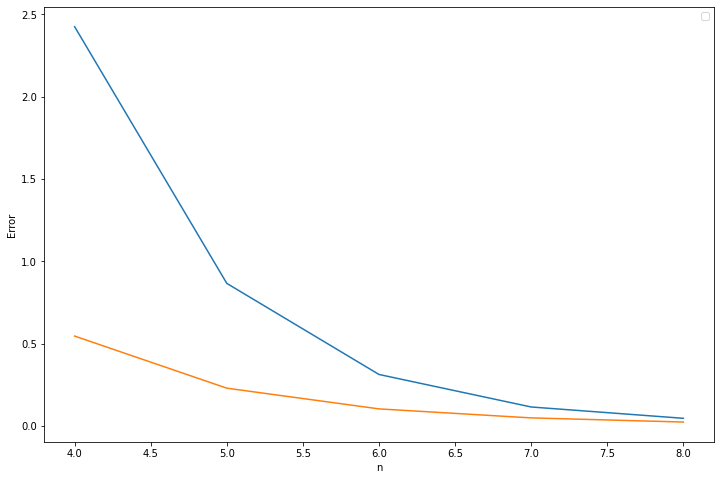

In [7]:
# YOUR CODE HERE

l2 = []
linfty = []

for i in range(len(deltas_x)):
    delta_x = deltas_x[i]
    N = Ns[i]

    xs = numpy.linspace(a, b, N + 2)
    real_ys = 8 - 9 * numpy.cos(3 * xs)
    cal_ys = compute_dbl_prime(lambda x: 2 + x + 4 * x ** 2 + numpy.cos(3 * x), a, b, N)

    # plt.figure(figsize=(12, 8))
    # plt.plot(xs, cal_ys)
    # plt.plot(xs, real_ys)
    # plt.xlabel("n")
    # plt.ylabel("Error")
    # plt.title(delta_x)
    # plt.legend

    l2.append(numpy.linalg.norm(real_ys - cal_ys, 2))
    linfty.append(numpy.linalg.norm(real_ys - cal_ys, numpy.inf))

plt.figure(figsize=(12, 8))
plt.plot(pws, l2)
plt.plot(pws, linfty)
plt.xlabel("n")
plt.ylabel("Error")
plt.legend(["L2 Norm", "Infty Norm"])
plt.legend()
plt.show()

**Reason:**

1. for $n < 8$, $\Delta x$ is not so small, hence the floating point won't cause large truncating errors.
2. as the step size $\Delta x$ descreases, the upper bound of calculated derivatives are also descresing. And the approximation of leftmost and rightmost point (switched forward and backward finite differences) also becomes more precise.
3. the norms are equivalent and $L_\infty$ norm doesn't concern with array lengths.

## 2

**(a)** [20] Show how to derive analytically the backward finite difference approximation to the 1st derivative that is 2nd order accurate assuming a stencil that has equal width between the stencil points.  You can use the numerical method introduced in the lecture notes to check your work but you must show how to derive the coefficients analytically as well (you can use the procedure the function is based on).  Also make sure to explicitly find the leading order form of the truncation error $\tau$.

Expand $f(x)$ around $x$, we have

$$f(x-\Delta x) = f(x) - \Delta x f'(x) +\Delta x^2\dfrac{f''(\zeta_1)}{2!} $$

$$f(x-\Delta x) = f(x) - \Delta x f'(x) +\Delta x^2\dfrac{f''(x)}{2!} -\Delta x^3 \dfrac{f'''(x)}{3!}+\Delta x^4 \dfrac{f''''(\eta_1)}{4!}$$

$$f(x-\Delta x) = f(x) - \Delta x f'(x) +\Delta x^2\dfrac{f''(x)}{2!} -\Delta x^3 \dfrac{f'''(x)}{3!}+\Delta x^4 \dfrac{f''''(x)}{4!} - \Delta x^5 \dfrac{f^{(5)}(x)}{5!} + \Delta x^6 \dfrac{f''''(\mu_1)}{6!}$$

together with

$$f(x-2\Delta x) = f(x) - 2\Delta x f'(x) +4\Delta x^2\dfrac{f''(\zeta_2)}{2!} $$

$$f(x-2\Delta x) = f(x) - 2\Delta x f'(x) +4\Delta x^2\dfrac{f''(x)}{2!} -8\Delta x^3 \dfrac{f'''(x)}{3!}+16\Delta x^4 \dfrac{f''''(\eta_2)}{4!}$$

$$f(x-2\Delta x) = f(x) - 2\Delta x f'(x) +4\Delta x^2\dfrac{f''(x)}{2!} -8\Delta x^3 \dfrac{f'''(x)}{3!}+16\Delta x^4 \dfrac{f''''(x)}{4!} - 32\Delta x^5 \dfrac{f^{(5)}(x)}{5!} + 64\Delta x^6 \dfrac{f''''(\mu_1)}{6!}$$

and

$$f(x-3\Delta x) = f(x) - 3\Delta x f'(x) +3^2\Delta x^2\dfrac{f''(\zeta_3)}{2!} $$

$$f(x-3\Delta x) = f(x) - 3\Delta x f'(x) +3^2\Delta x^2\dfrac{f''(x)}{2!} -3^3\Delta x^3 \dfrac{f'''(x)}{3!}+3^4\Delta x^4 \dfrac{f''''(\eta_3)}{4!}$$

$$f(x-3\Delta x) = f(x) - 3\Delta x f'(x) +3^2\Delta x^2\dfrac{f''(x)}{2!} -3^3\Delta x^3 \dfrac{f'''(x)}{3!}+3^4\Delta x^4 \dfrac{f''''(x)}{4!} - 3^5\Delta x^5 \dfrac{f^{(5)}(x)}{5!} + 3^6\Delta x^6 \dfrac{f''''(\mu_3)}{6!}$$

hence 

$$\dfrac{3 f(x)- 4 f(x-\Delta x) + f(x - 2\Delta)}{2\Delta x}-f'(x)=-\dfrac{\Delta x^2}{3} \dfrac{-4f'''(\zeta_1)+3f'''(\zeta_2)}{3!}=O(\Delta x^2)$$

and

$$\dfrac{2f(x)-5f(x-\Delta x)+4f(x-2\Delta x)-f(x-3\Delta x)}{\Delta x^2}-f''(x)=-\dfrac{11\Delta x^2}{12} \dfrac{-5f^{(4)}(\mu_1)+4f^{(4)}(\mu_2)-f^{(4)}(\mu_3)}{4!}=O(\Delta x^2)$$

where $\zeta_1, \zeta_2 \in (x-\Delta x, x)$, $\eta_1, \eta_2 \in (x - 2\Delta x, x)$

therefore 

$$f'(x)\approx\dfrac{3 f(x)- 4 f(x-\Delta x) + f(x - 2\Delta)}{2\Delta x}$$

$$f''(x)\approx\dfrac{2f(x)-5f(x-\Delta x)+4f(x-2\Delta x)-f(x-3\Delta x)}{\Delta x^2}$$


**(b)** [15] Write a function that computes this 1st derivative of an arbitrary function $f(x)$ using the backward difference approximation you used above.  The function should accept a set of points `x` to evaluate the 1st derivative at and the function `f`.  For the first points in `x` use the forward difference approximation that mirrors the one you just found (see the lecture notes).

In [8]:
def compute_prime(x, f):
    """Compute the first derivative"""
    f_prime = [(3 * f(x[i]) - 4 * f(x[i - 1]) + f(x[i - 2])) / (2 * x[i] - 2 * x[i - 1]) for i in range(2, len(x))]
    f_prime = [
        (3 * f(x[0]) - 4 * f(x[1]) + f(x[2])) / (2 * x[0] - 2 * x[1]), #f_prime[0], 
        (3 * f(x[1]) - 4 * f(x[2]) + f(x[3])) / (2 * x[1] - 2 * x[2]),#f_prime[0]
    ] + f_prime
    return f_prime

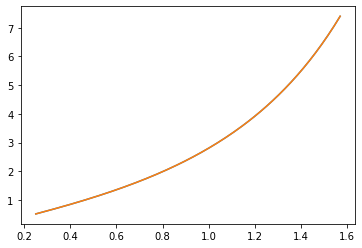

Success!


In [9]:
f = lambda x: x**3 / numpy.sin(x)
f_prime = lambda x: -x**3 * numpy.cos(x) / numpy.sin(x)**2 + 3.0 * x**2 / numpy.sin(x)
x = numpy.linspace(0.25, 0.5 * numpy.pi, 150)

plt.figure()
plt.plot(x, compute_prime(x, f))
plt.plot(x, f_prime(x))
plt.show()

# compute_prime(x, f) - f_prime(x)

numpy.testing.assert_allclose(compute_prime(x, f), f_prime(x), atol=1e-3)
print("Success!")

**(c)** [15] Using your function above plot the derivative of the function and error convergence behavior for the functions.  
$$
    f(x) = \frac{x^3}{\sin x}, \quad \quad g(x) = |x - 3/2|, \quad \text{and} \quad h(x) = \left \{ \begin{aligned} 0 & & x < 3/2 \\ 1 & & x \ge 3/2 \end{aligned} \right .
$$
on the interval $x \in [1, 2]$.  Explain the behavior you see.

In [88]:
xs

array([1.                , 1.0050251256281406, 1.0100502512562815,
       1.015075376884422 , 1.020100502512563 , 1.0251256281407035,
       1.0301507537688441, 1.035175879396985 , 1.0402010050251256,
       1.0452261306532664, 1.050251256281407 , 1.0552763819095476,
       1.0603015075376885, 1.065326633165829 , 1.07035175879397  ,
       1.0753768844221105, 1.0804020100502512, 1.085427135678392 ,
       1.0904522613065326, 1.0954773869346734, 1.100502512562814 ,
       1.1055276381909547, 1.1105527638190955, 1.1155778894472361,
       1.120603015075377 , 1.1256281407035176, 1.1306532663316582,
       1.135678391959799 , 1.1407035175879396, 1.1457286432160805,
       1.150753768844221 , 1.1557788944723617, 1.1608040201005025,
       1.1658291457286432, 1.170854271356784 , 1.1758793969849246,
       1.1809045226130652, 1.185929648241206 , 1.1909547738693467,
       1.1959798994974875, 1.2010050251256281, 1.2060301507537687,
       1.2110552763819096, 1.2160804020100502, 1.2211055276381

-----f(x)-----


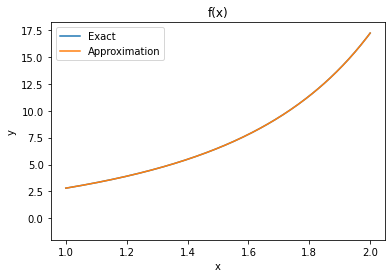

Max absolute error: 0.0008810101612830579

Max relative error: 5.115171131933128e-05



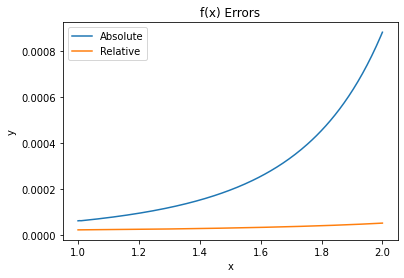

-----g(x)-----


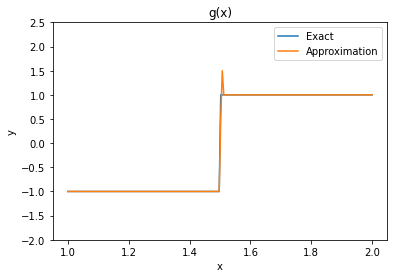

Max absolute error: 0.5

Max relative error: 0.5



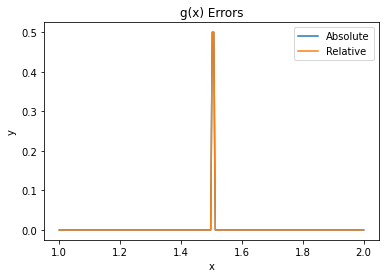

-----h(x)-----


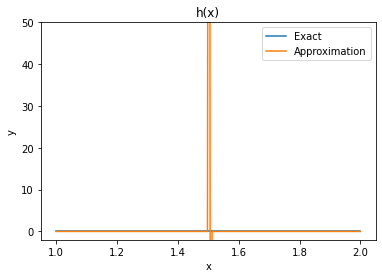

Max absolute error: 298.5000000000053

Max relative error: nan



C:\Users\35995\AppData\Local\Temp\ipykernel_36660\3860223406.py:44: RuntimeWarning: divide by zero encountered in true_divide
  re = numpy.nan_to_num(numpy.abs(da - nda) / da)
C:\Users\35995\AppData\Local\Temp\ipykernel_36660\3860223406.py:44: RuntimeWarning: invalid value encountered in true_divide
  re = numpy.nan_to_num(numpy.abs(da - nda) / da)
C:\Users\35995\AppData\Local\Temp\ipykernel_36660\3860223406.py:46: RuntimeWarning: divide by zero encountered in true_divide
  print("Max relative error: {}\n".format(numpy.linalg.norm(e / da, numpy.inf)))
C:\Users\35995\AppData\Local\Temp\ipykernel_36660\3860223406.py:46: RuntimeWarning: invalid value encountered in true_divide
  print("Max relative error: {}\n".format(numpy.linalg.norm(e / da, numpy.inf)))
c:\Python310\lib\site-packages\matplotlib\axes\_base.py:2924: RuntimeWarning: overflow encountered in double_scalars
  x0, x1 = inverse_trans.transform([x0t - delta, x1t + delta])


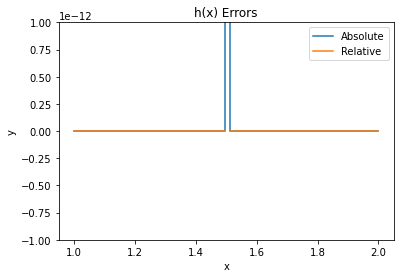

In [10]:
# YOUR CODE HERE
f = lambda x: x**3 / numpy.sin(x)
df = lambda x: -x**3 * numpy.cos(x) / numpy.sin(x)**2 + 3.0 * x**2 / numpy.sin(x)
g = lambda x: numpy.abs(x - 3 / 2)
dg = lambda x: -1 if x < 3 / 2 else 1
h = lambda x: 0 if x < 3 / 2 else 1
dh = lambda x: 0

xs = numpy.linspace(1, 2, 200)

fs = f(xs)
gs = numpy.vectorize(g)(xs)
hs = numpy.vectorize(h)(xs)

dfs = df(xs)
dgs = numpy.vectorize(dg)(xs)
dhs = numpy.vectorize(dh)(xs)

ndfs = compute_prime(xs, f)
ndgs = compute_prime(xs, g)
ndhs = compute_prime(xs, h)

# f
i = 10
for da, nda, title in [
    (dfs, ndfs, "f(x)"),
    (dgs, ndgs, "g(x)"),
    (dhs, ndhs, "h(x)")
]:
    print("-----" + title + "-----")
    plt.figure(i)
    plt.plot(xs, da)
    plt.plot(xs, nda)
    plt.xlabel("x")
    plt.ylabel("y")
    plt.ylim([-2, min(max(nda) + 1, 50)])
    plt.title(title)
    plt.legend(["Exact", "Approximation"])
    plt.show()
    i += 1

    plt.figure(i)
    e = numpy.abs(da - nda)
    re = numpy.nan_to_num(numpy.abs(da - nda) / da)
    print("Max absolute error: {}\n".format(numpy.linalg.norm(e, numpy.inf)))
    print("Max relative error: {}\n".format(numpy.linalg.norm(e / da, numpy.inf)))
    plt.plot(xs, e)
    plt.plot(xs, re)
    plt.xlabel("x")
    plt.ylabel("y")
    plt.legend(["Absolute", "Relative"])
    plt.title(title + " Errors")
    plt.show()
    i += 1

**Answer:**

1. As the function value increases, the absolute error increases, but the relative error keep steady for smooth function, since the approximated error is uniformly of the same order.
2. For $g(x)$, there is a sharp discontinous point at $x=3/2$ where the first derivative changes from $-1$ to $1$, so there shows some kind of unstable behaviour around $x=3/2$.
3. For $h(x)$, the function value changes suddenly at $x=3/2$, resulting in infinite first derivative, numerically, as we take finite step size, there will be an extremely large number calculated around $x=3/2$.

# 3
Solving the following PDEs showing the relevant steps and plot a few time snapshots of the solution.

**(a)** [15] $u_t = \kappa u_{xx}$ with $x \in \Omega = (0, L)$, the boundary conditions $u(0, t)_x = 0$ and $u_x(L, t) = 0$, and the initial condition $u(x, 0) = 2 - \cos\left(\frac{\pi x}{L} \right) + 3 \cos\left(\frac{3 \pi x}{L} \right)$.  When plotting the solution pick a value for $L$ and play with values of $\kappa$.  Make sure your solution makes sense as $t \rightarrow \infty$.

We'll discrete the space and solve along the time. i.e. 

after the discretization, we got an ODE equation about time $u_t=f(t,u)$:

$$u_t=\kappa \dfrac{u_{i+1}-2u_i+u_{i-1}}{h^2}$$ 

the we can apply numerical methods to solve it, here we adopt the 4-th order Runge-Kutta Method, for an ODE $x(t) = f(x,t)$:

```
k1 = h * f(x, t)
k2 = h * f(x + k1/2, t + h/2)
k3 = h * f(x + k2/2, t + h/2)
k4 = h * f(x + k3, t + h)
x(t+h) = x(t) + (k1 + 2*k2 + 2*k3 + k4)/6
```

In [62]:
# YOUR CODE HERE
k = 1
dt = 0.00005
Nx = 100
Nt = 10000
L = numpy.pi
dx = (L - 0) / Nx

res = {}

ks = [1, 2, 5]

for k in ks:
    def f(us):
        dut = numpy.array([0.0] * len(us))
        mx = len(us) - 1
        for i in range(1, mx):
            dut[i] = k * (us[i + 1] - 2 * us[i] + us[i - 1])
        dut[0] = k * (-us[2] + 4 * us[1] - 5 * us[0] + 2 * us[0])
        dut[mx] = k * (2 * us[mx] - 5 * us[mx] + 4 * us[mx - 1] - us[mx - 2])
        return dut 

    u0x = lambda x: 2 - numpy.cos(numpy.pi * x / L) + 3 * numpy.cos(3 * numpy.pi * x / L)

    xs = numpy.linspace(0, L, Nx)
    us = u0x(xs)

    res[k] = [us]

    for i in range(Nt):
        last_us = res[k][-1]

        k1 = dt * f(last_us)
        k2 = dt * f(last_us + k1 / 2)
        k3 = dt * f(last_us + k2 / 2)
        k4 = dt * f(last_us + k3)

        new_us = last_us + (k1 + 2 * k2 + 2 * k3 + k4) / (6 * dx ** 2)

        res[k].append(new_us)


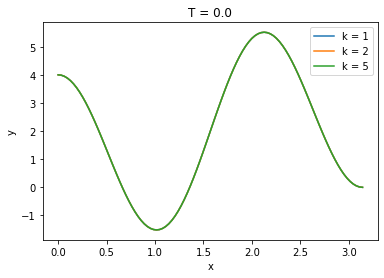

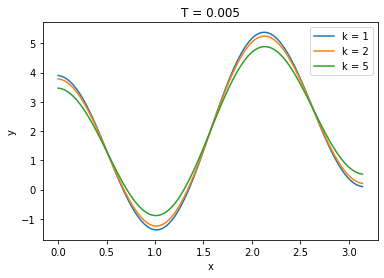

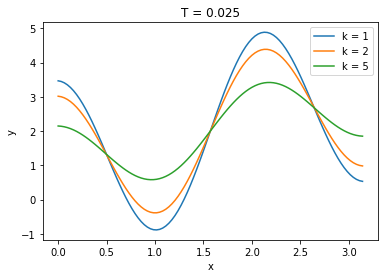

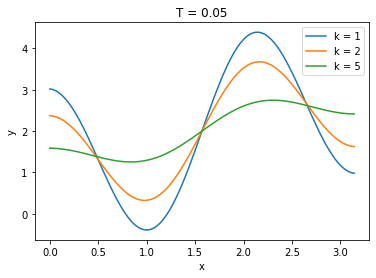

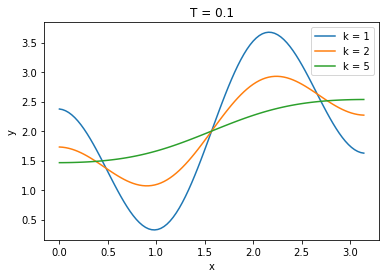

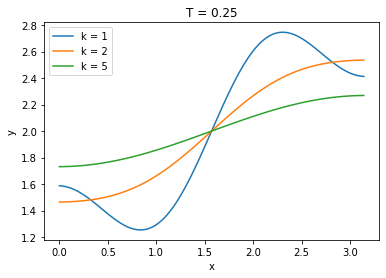

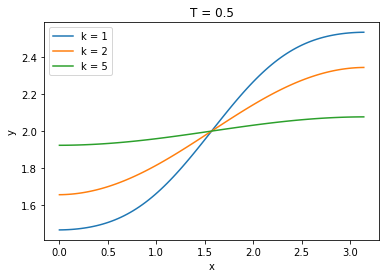

In [64]:

for i in [0, 100, 500, 1000, 2000, 5000, 10000]:
    plt.figure()
    plt.title("T = {}".format(dt * i))
    plt.xlabel("x")
    plt.ylabel("y")
    for k in ks:
        us = res[k][i]
        plt.plot(xs, us)
    plt.legend(list(map(lambda x: "k = " + str(x),ks)))
    plt.show()

In [ ]:
from matplotlib.animation import ArtistAnimation as AA
from IPython import display 

frames = []
fig = plt.figure()
plt.xlim([0, L])
plt.ylim([-2, 6])

for i in range(0, len(res), len(res) // 100):
    # plt.title("T = {}".format(dt * i))
    frame = plt.plot(numpy.array(xs), numpy.array(us), color="orange")
    frames.append(frame)

ani = AA(fig, frames)
plt.show()
# html = display.HTML(ani.to_jshtml())
# display.display(html)
# plt.close()


**(b)** [15] Solve the PDE $u_t + \left(\frac{1}{2}u^2\right)_x = 0$ where $x \in \Omega = \mathbb R$ and the initial conditions
$$ 
    u(x,0) = \left \{ \begin{aligned}
        1 & & x \leq 0 \\
        2 & & x > 0
    \end{aligned} \right .
$$
In addition to plotting the solution also mark the edges of interesting regions such as the rarefaction fan or the shock.

$u_t=-uu_x$, adopt the same method as the last question. Discrete space:

$$u_t=-u_i\dfrac{u_{i+1}-u_{i-1}}{2h}$$

we also test 4 order formula

$$u_t=-u_i\dfrac{-u_{i+2}+8u_{i+1}-8u_{i-1}+u_{i-2}}{12h}$$

In [21]:
# YOUR CODE HERE
k = 1
dt = 0.000025
Nx = 100
Nt = 20000
R = 5
L = -5
dx = (R - L) / Nx

ts = [dt * i for i in range(Nt)]

def f1(us):
    dut = numpy.array([0.0] * len(us))
    mx = len(us) - 1
    for i in range(1, mx):
        dut[i] = -(0.5 * (us[i + 1] ** 2) - 0.5 * (us[i - 1] ** 2))
    dut[0] = -2 * (0.5 * (us[1] ** 2) - 0.5 * (us[0] ** 2))
    dut[mx] = -2 * (0.5 * (us[mx] ** 2) - 0.5 * (us[mx - 1] ** 2))
    return dut 

def f2(us):
    dut = numpy.array([0.0] * len(us))
    mx = len(us) - 1
    for i in range(1, mx):
        dut[i] = -(us[i + 1] - us[i - 1]) * us[i]
    dut[0] = -2 * (us[1] - us[0]) * (us[1] + us[0]) / 2
    dut[mx] = -2 * (us[mx] - us[mx - 1]) * (us[mx] + us[mx - 1]) / 2
    return dut 

def f3(us):
    dut = numpy.array([0.0] * len(us))
    mx = len(us) - 1
    for i in range(2, mx - 1):
        dut[i] = -(-us[i + 2] + 8 * us[i + 1] - 8 * us[i - 1] + us[i - 2]) * us[i]
    for i in [0, 1]:
        dut[0] = -6 * (-us[i + 2] + 4 * us[i + 1] - 3 * us[i]) * (us[1] + us[0]) / 2
    for i in [mx, mx - 1]:
        dut[i] = 6 * (-us[i - 2] + 4 * us[i - 1] - 3 * us[i]) * (us[1] + us[0]) / 2
    return dut 

xs = numpy.linspace(L, R, Nx)
us = 2 - (xs < 0)

pool = [f1, f2, f3]
factor = {f1: 2 * dx, f2: 2 * dx, f3: 12 * dx}
legends = {f1: "f1", f2: "f2", f3: "f3"}

res = {x: [us] for x in pool}

for i in range(Nt - 1):
    for tf in pool:
        last_us = res[tf][-1]
        k1 = dt * tf(last_us)
        k2 = dt * tf(last_us + k1 / 2)
        k3 = dt * tf(last_us + k2 / 2)
        k4 = dt * tf(last_us + k3)

        new_us = last_us + (k1 + 2 * k2 + 2 * k3 + k4) / (6 * factor[tf])

        res[tf].append(new_us)

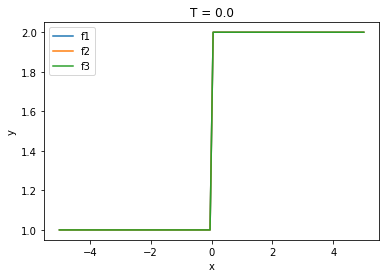

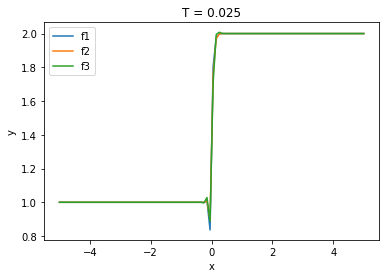

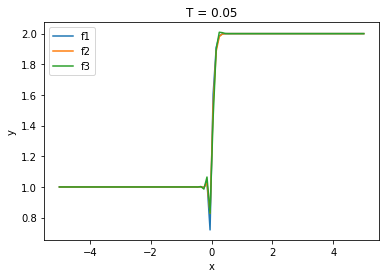

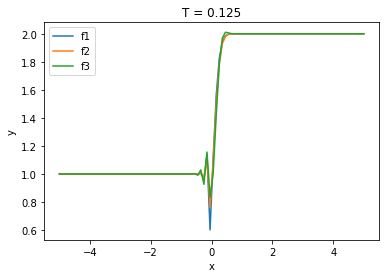

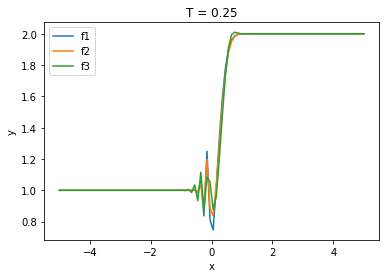

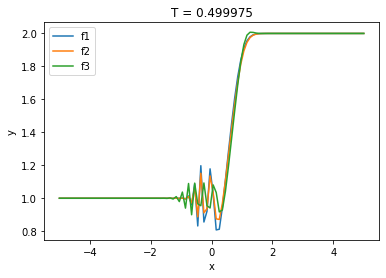

In [22]:
for i in [0, 1000, 2000, 5000, 10000, 20000 - 1]:
    plt.figure()
    plt.title("T = {}".format(dt * i))
    plt.xlabel("x")
    plt.ylabel("y")
    for tf in pool:
        us = res[tf][i]
        plt.plot(xs, us)
    plt.legend(legends.values())
    plt.show()

C:\Users\35995\AppData\Local\Temp\ipykernel_24040\1931144306.py:14: UserWarning: Matplotlib is currently using module://matplotlib_inline.backend_inline, which is a non-GUI backend, so cannot show the figure.
  fig.show()


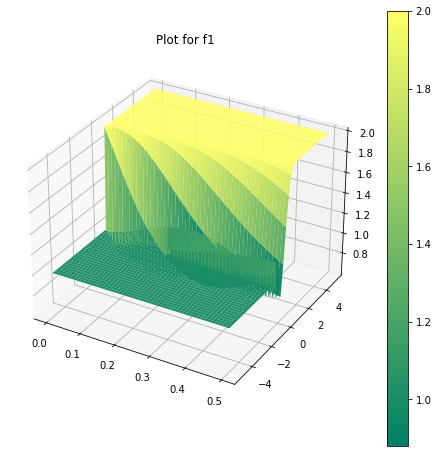

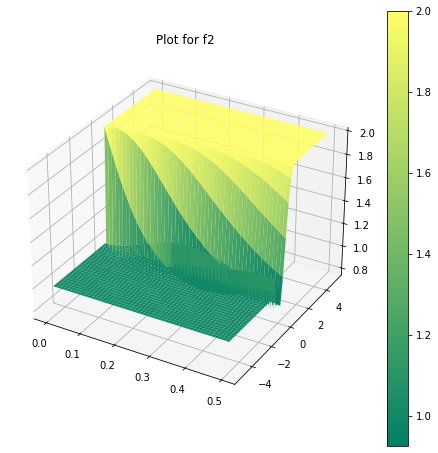

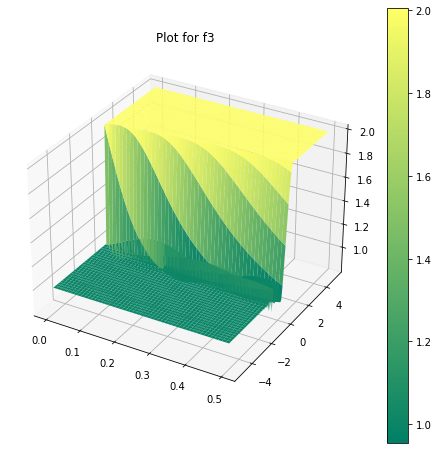

In [27]:
from mpl_toolkits.mplot3d import Axes3D

for tf in pool:
    fig = plt.figure(figsize = (8, 8))
    ax = fig.add_subplot(111, projection="3d")

    T, X = numpy.meshgrid(ts, xs)

    U = numpy.array(res[tf]).transpose().reshape(T.shape)

    surf = ax.plot_surface(T, X, U, cmap='summer', linewidth=0)
    fig.colorbar(surf)
    ax.set_title("Plot for " + legends[tf])
    fig.show()